# RPS、量价、低位与超跌：固定规则历史拆解

## tl;dr
没有一组通过本轮登记的跨两段历史与费用压力门槛。RPS＋量价早期较好、后期较弱；低位转强确认弱于仅低位；超跌确认有弱线索但后期不足。不能据此断言整个概念无效，也不能宣称找到盈利策略。

## Context & Methods

### Key Assumptions
前复权价格只作表现代理；历史已被使用。统一下一日开盘进入、其后第20市场日开盘观察；5日是敏感性。固定8组，无调参。各段未来标签在段末截断，信号与未来标签分开保存。区间以月均同日差做3月连续块重抽样，各段6对比使用99.1667%区间。协议、登记代码与数据指纹可检查。

股票目录可能存在幸存者偏差；未核实原始价限价、整手、现金分红或组合资金；不得把图表当净值曲线。

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
out = Path.cwd()
summary = pd.read_csv(out / 'summary.csv')
contrasts = pd.read_csv(out / 'contrasts.csv')
quality = json.loads((out / 'quality.json').read_text(encoding='utf-8'))
verification = json.loads((out / 'verification.json').read_text(encoding='utf-8'))
plt.rcParams.update({'font.family':'Microsoft YaHei', 'axes.unicode_minus':False, 'figure.dpi':120})
names = {'universe': '同日研究集合', 'rps_only': '仅RPS', 'pv_only': '仅量价', 'rps_pv': 'RPS＋量价', 'low_only': '仅低位', 'low_turn': '低位转强', 'oversold_only': '仅超跌', 'oversold_confirm': '超跌＋确认'}

## Data
控制源：同花顺本地前复权表，兼容文件名tdx_stock_daily_with_rps.parquet。5224只股票均在最近250个市场日有记录，因此不能证明完整历史退市覆盖。质量指标和独立抽样核对如下；抽样不是全量成交审计。

In [2]:
display(pd.DataFrame([quality])[['rows','securities','first','last','duplicate_keys','invalid_rows','impossible_ohlc','early_ending_before_last_250_sessions']])
display(pd.DataFrame([verification]))

,rows,securities,first,last,duplicate_keys,invalid_rows,impossible_ohlc,early_ending_before_last_250_sessions
0,10108785,5224,2016-08-22,2026-09-30,0,0,0,0


,sampled_labels,passed,output_fingerprints_match,signal_label_counts_reconcile,costs_reconcile,code_snapshot_verified,limitation
0,160,160,True,True,True,True,sampled labels only; no independent complete s...


## Results
### 1. 两段历史的20日价格表现代理
扣费前、非年化、非组合收益。完整8组均展示，不只公布赢家。

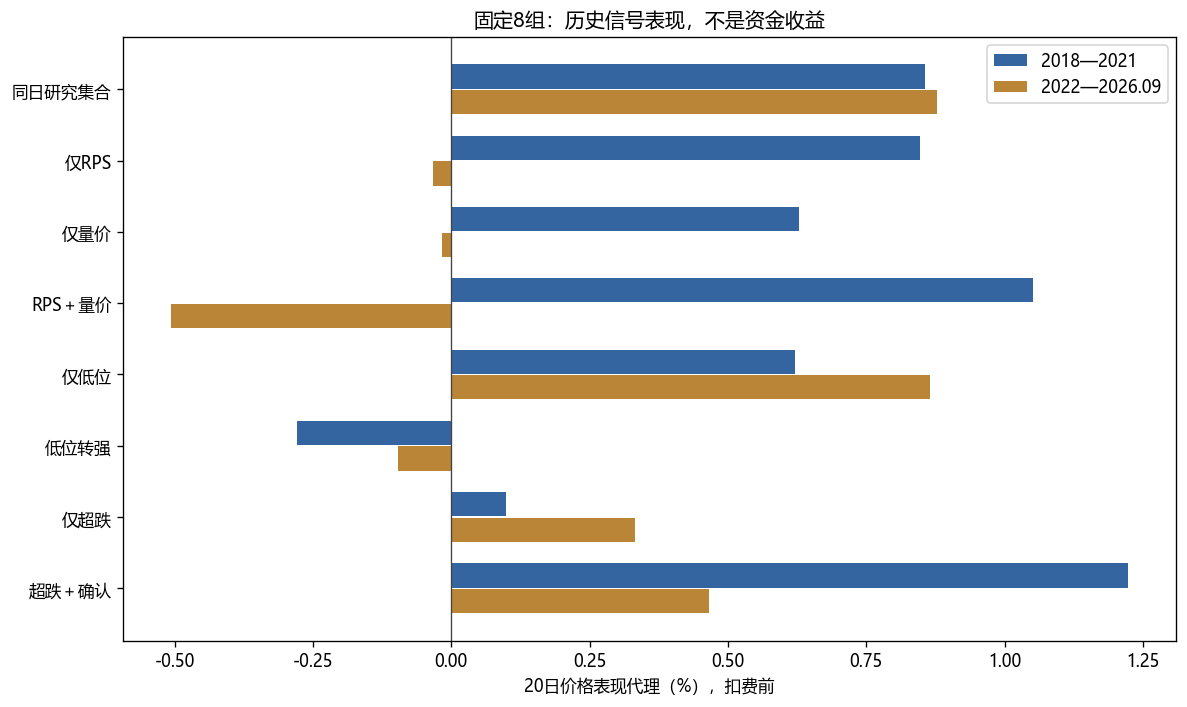

,model,period,signals,labels,unavailable,gross_daily_mean_pct,cost_proxy_daily_mean_pct
1,low_only,early,860866,841428,19438,0.622,-0.378
3,low_turn,early,64326,62968,1358,-0.279,-1.279
5,oversold_confirm,early,4961,4814,147,1.223,0.223
7,oversold_only,early,26637,25801,836,0.099,-0.901
9,pv_only,early,38697,37210,1487,0.629,-0.371
11,rps_only,early,504579,488654,15925,0.848,-0.152
13,rps_pv,early,12094,11616,478,1.051,0.051
15,universe,early,2175805,2103790,72015,0.856,-0.144
17,low_only,late,1661073,1602106,58967,0.866,-0.134
19,low_turn,late,120478,116701,3777,-0.096,-1.096


In [3]:
selected = summary[(summary.horizon==20)&(summary.friction_pct==1)].copy()
order = list(names)
pivot = selected.pivot(index='model',columns='period',values='gross_daily_mean_pct').reindex(order)
fig, ax = plt.subplots(figsize=(10,6))
y = list(range(len(order)))
ax.barh([v-.18 for v in y], pivot.early, height=.34, label='2018—2021', color='#3565a0')
ax.barh([v+.18 for v in y], pivot.late, height=.34, label='2022—2026.09', color='#bb8537')
ax.set_yticks(y,[names[m] for m in order]); ax.invert_yaxis(); ax.axvline(0,color='#444444',linewidth=.8)
ax.set_xlabel('20日价格表现代理（%），扣费前'); ax.set_title('固定8组：历史信号表现，不是资金收益')
ax.legend(); fig.tight_layout(); fig.savefig(out/'proxy-comparison.png'); plt.show()
display(selected[['model','period','signals','labels','unavailable','gross_daily_mean_pct','cost_proxy_daily_mean_pct']].round(3))

### 2. 主20日同日增量差与统计区间
点估计及区间都基于月均差。不是因果实验，不消除历史选择偏差。

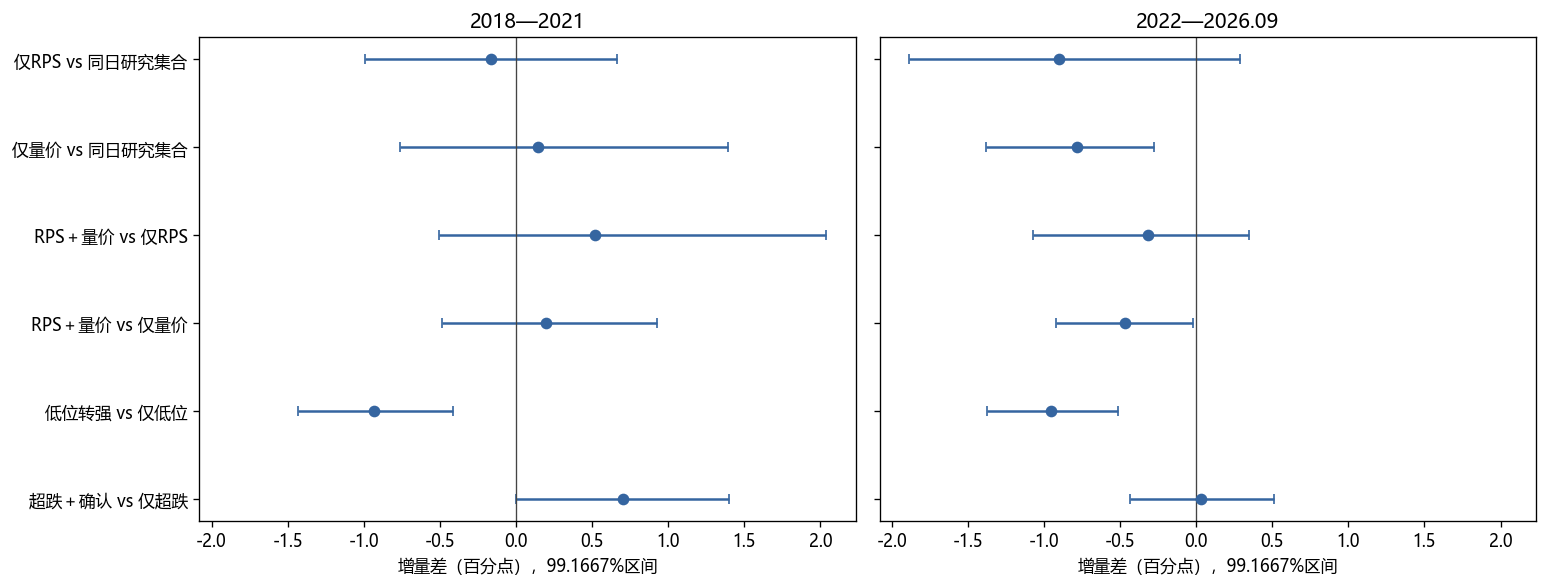

,candidate,baseline,period,horizon,paired_days,months,mean_pp,daily_mean_pp,lo_pp,hi_pp
0,rps_only,universe,early,20,952,48,-0.161,-0.008,-0.990,0.664
1,pv_only,universe,early,20,882,48,0.148,-0.115,-0.761,1.391
2,rps_pv,rps_only,early,20,840,48,0.522,0.143,-0.507,2.037
3,rps_pv,pv_only,early,20,840,48,0.199,0.321,-0.483,0.924
4,low_turn,low_only,early,20,952,48,-0.934,-0.901,-1.435,-0.415
5,oversold_confirm,oversold_only,early,20,698,48,0.701,0.761,-0.002,1.399
6,rps_only,universe,late,20,1129,56,-0.905,-0.912,-1.884,0.289
7,pv_only,universe,late,20,1109,56,-0.785,-0.788,-1.380,-0.279
8,rps_pv,rps_only,late,20,1085,56,-0.314,-0.355,-1.073,0.345
9,rps_pv,pv_only,late,20,1085,56,-0.468,-0.471,-0.918,-0.018


In [4]:
pairs = list(dict.fromkeys(zip(contrasts.candidate,contrasts.baseline)))
fig, axes = plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
for ax, period, label in zip(axes,['early','late'],['2018—2021','2022—2026.09']):
    c = contrasts[(contrasts.horizon==20)&(contrasts.period==period)].set_index(['candidate','baseline']).reindex(pairs)
    ax.errorbar(c.mean_pp,range(len(c)),xerr=[c.mean_pp-c.lo_pp,c.hi_pp-c.mean_pp],fmt='o',capsize=3,color='#3565a0')
    ax.set_title(label); ax.axvline(0,color='#444444',linewidth=.8); ax.set_xlabel('增量差（百分点），99.1667%区间')
axes[0].set_yticks(range(len(pairs)),[names[a]+' vs '+names[b] for a,b in pairs]); axes[0].invert_yaxis()
fig.tight_layout(); fig.savefig(out/'paired-intervals.png'); plt.show()
display(contrasts[contrasts.horizon==20].round(3))

## Takeaways
当前规则没有证明稳定可兑现优势。超跌确认后期相对仅超跌月均差约+0.031个百分点，区间约[-0.435,+0.508]，不能宣称有效。低位转强两段均弱于仅低位，不能因名字听起来合理就保留确认。

下一步先补历史退市/证券状态、原始价交易限制，并诊断规模与波动暴露；不修改本次阈值、删除失败年份或追加网格。若另提规则须新编号。研究源代码、标签、统计和160个抽样核对均可复查。